In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
df = pd.read_csv("Documents/Spain_Top50_Analysis/Data/Atlantic_Spain.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [13]:
df.head()

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,18-05-2024,1,Supernova,Saiko,84,190909,single,1,False,https://i.scdn.co/image/ab67616d0000b273c3f5b9...
1,18-05-2024,2,EL TONTO,Lola Indigo,83,187986,album,11,False,https://i.scdn.co/image/ab67616d0000b273daab36...
2,18-05-2024,3,Acróstico,Shakira,81,170785,single,1,False,https://i.scdn.co/image/ab67616d0000b273bd6bbd...
3,18-05-2024,4,BESO,ROSALÍA & Rauw Alejandro,96,194543,single,3,False,https://i.scdn.co/image/ab67616d0000b2734d6cf0...
4,18-05-2024,5,El Merengue,Marshmello & Manuel Turizo,91,189668,single,1,False,https://i.scdn.co/image/ab67616d0000b273f40467...


In [14]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 27800
Columns: 10


In [15]:
print(df.columns.tolist())

['date', 'position', 'song', 'artist', 'popularity', 'duration_ms', 'album_type', 'total_tracks', 'is_explicit', 'album_cover_url']


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27800 entries, 0 to 27799
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   date             27800 non-null  object
 1   position         27800 non-null  int64 
 2   song             27800 non-null  object
 3   artist           27800 non-null  object
 4   popularity       27800 non-null  int64 
 5   duration_ms      27800 non-null  int64 
 6   album_type       27800 non-null  object
 7   total_tracks     27800 non-null  int64 
 8   is_explicit      27800 non-null  bool  
 9   album_cover_url  27800 non-null  object
dtypes: bool(1), int64(4), object(5)
memory usage: 1.9+ MB


In [17]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,27800,555,01-03-2025,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
position,27800.0,NaN,NaN,NaN,25.5,14.431129,1.0,13.0,25.5,38.0,50.0
song,27800,545,La Bachata,539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artist,27800,306,Myke Towers,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,27800.0,NaN,NaN,NaN,81.123957,10.088455,0.0,76.0,82.0,87.0,100.0
duration_ms,27800.0,NaN,NaN,NaN,197473.678237,43371.454913,90613.0,168594.0,191254.0,218119.0,555071.0
album_type,27800,2,single,16041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_tracks,27800.0,NaN,NaN,NaN,7.202554,7.683734,1.0,1.0,1.0,15.0,49.0
is_explicit,27800,2,False,16143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
album_cover_url,27800,419,https://i.scdn.co/image/ab67616d0000b2737b1fc5...,659,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
df.isnull().sum().sort_values(ascending=False)

date               0
position           0
song               0
artist             0
popularity         0
duration_ms        0
album_type         0
total_tracks       0
is_explicit        0
album_cover_url    0
dtype: int64

In [19]:
print("Number of unique dates:", df["date"].nunique()
      if "date" in df.columns else "date column missing")

print("Duplicate rows:", df.duplicated().sum())

print("\nColumn names:")
for col in df.columns:
    print("-", col)

Number of unique dates: 555
Duplicate rows: 15

Column names:
- date
- position
- song
- artist
- popularity
- duration_ms
- album_type
- total_tracks
- is_explicit
- album_cover_url


In [20]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage
date,0,0.0
position,0,0.0
song,0,0.0
artist,0,0.0
popularity,0,0.0
duration_ms,0,0.0
album_type,0,0.0
total_tracks,0,0.0
is_explicit,0,0.0
album_cover_url,0,0.0


In [21]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 15


In [22]:
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_rows.head(10)

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
14351,01-03-2025,2,Manos Rotas,DELLAFUENTE & Morad,85,168594,single,1,False,https://i.scdn.co/image/ab67616d0000b2731a176d...
14352,01-03-2025,3,LA FALDA,Myke Towers,94,174229,album,23,True,https://i.scdn.co/image/ab67616d0000b273c75c05...
14353,01-03-2025,4,X'CLUSIVO,Gonzy,81,175586,single,1,True,https://i.scdn.co/image/ab67616d0000b2730d794d...
14354,01-03-2025,5,LUNA,Feid,97,196800,album,10,False,https://i.scdn.co/image/ab67616d0000b273f1aad8...
14355,01-03-2025,6,M.A.I,Milo j,89,184027,album,10,False,https://i.scdn.co/image/ab67616d0000b27398ee8f...
14356,01-03-2025,7,Una Foto Remix (feat. Emilia),Mesita & Nicki Nicole & Tiago PZK,92,243898,single,1,False,https://i.scdn.co/image/ab67616d0000b273d7e325...
14358,01-03-2025,9,Mamichula - con Nicki Nicole,Trueno,88,219201,album,10,False,https://i.scdn.co/image/ab67616d0000b273f4483d...
14361,01-03-2025,12,No Te Quieren Conmigo,Gaby Music & Lunay & Luar La L,89,252040,single,1,False,https://i.scdn.co/image/ab67616d0000b2732a3429...
14366,01-03-2025,17,UNA BACHATA,Lola Indigo,77,157846,album,7,False,https://i.scdn.co/image/ab67616d0000b27346dd0b...
14368,01-03-2025,19,A 300,JC Reyes & Pedro Calderon & Blacknife,79,169208,single,1,False,https://i.scdn.co/image/ab67616d0000b273827446...


In [23]:
if "date" in df.columns:
    print(df["date"].head())
    print("Date data type:", df["date"].dtype)
else:
    print("The dataset does not contain a column named 'date'.")

0    18-05-2024
1    18-05-2024
2    18-05-2024
3    18-05-2024
4    18-05-2024
Name: date, dtype: object
Date data type: object


In [24]:
if "position" in df.columns:
    print("Missing positions:", df["position"].isna().sum())

    print("Minimum position:", df["position"].min())
    print("Maximum position:", df["position"].max())

    invalid_positions = df[
        ~df["position"].between(1, 50)
    ]

    print("Positions outside 1–50:", len(invalid_positions))
    display(invalid_positions.head(10))
else:
    print("The dataset does not contain a 'position' column.")

Missing positions: 0
Minimum position: 1
Maximum position: 50
Positions outside 1–50: 0


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url


In [25]:
for col in ["song", "artist"]:
    if col in df.columns:
        print(f"\nExamples from {col}:")
        print(df[col].dropna().head(10).tolist())


Examples from song:
['Supernova', 'EL TONTO', 'Acróstico', 'BESO', 'El Merengue', 'Mami Chula', 'Classy 101', 'Clavaito', 'TQG', 'Yandel 150']

Examples from artist:
['Saiko', 'Lola Indigo', 'Shakira', 'ROSALÍA & Rauw Alejandro', 'Marshmello & Manuel Turizo', 'Jhayco & Quevedo', 'Feid & Young Miko', 'Chanel & Abraham Mateo', 'KAROL G', 'Yandel']


In [68]:
from pathlib import Path

output_folder = Path("Documents/Spain_Top50_Analysis/Data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

df.to_csv(
    output_folder / "spain_top50_cleaning_stage.csv",
    index=False
)

print("Working dataset saved successfully.")

Working dataset saved successfully.


In [27]:
# Count playlist records for each date
if "date" in df.columns:
    daily_counts = df.groupby("date").size()

    print("Number of dates:", len(daily_counts))
    print("\nDaily playlist record counts:")
    print(daily_counts.describe())

    # Find dates that do not have 50 records
    unusual_dates = daily_counts[daily_counts != 50]

    print("\nDates with other than 50 records:", len(unusual_dates))
    display(unusual_dates.head(20))
else:
    print("Date column is missing.")

Number of dates: 555

Daily playlist record counts:
count    555.000000
mean      50.090090
std        2.122382
min       50.000000
25%       50.000000
50%       50.000000
75%       50.000000
max      100.000000
dtype: float64

Dates with other than 50 records: 1


date
01-03-2025    100
dtype: int64

In [28]:
required_cols = {"date", "song"}

if required_cols.issubset(df.columns):
    duplicate_song_dates = df[
        df.duplicated(subset=["date", "song"], keep=False)
    ].sort_values(["date", "song"])

    print(
        "Rows involved in repeated song-date combinations:",
        len(duplicate_song_dates)
    )

    display(duplicate_song_dates.head(20))
else:
    print("The required date/song columns are not available.")

Rows involved in repeated song-date combinations: 122


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
14368,01-03-2025,19,A 300,JC Reyes & Pedro Calderon & Blacknife,79,169208,single,1,False,https://i.scdn.co/image/ab67616d0000b273827446...
14418,01-03-2025,19,A 300,JC Reyes & Pedro Calderon & Blacknife,79,169208,single,1,False,https://i.scdn.co/image/ab67616d0000b273827446...
14391,01-03-2025,42,ASI ES LA VIDA,Enrique Iglesias & Maria Becerra,84,172095,single,1,False,https://i.scdn.co/image/ab67616d0000b2733d2a29...
14440,01-03-2025,41,ASI ES LA VIDA,Enrique Iglesias & Maria Becerra,84,172095,single,1,False,https://i.scdn.co/image/ab67616d0000b2733d2a29...
14382,01-03-2025,33,BABY HELLO,Rauw Alejandro,78,222461,album,14,True,https://i.scdn.co/image/ab67616d0000b273f79b1a...
14433,01-03-2025,34,BABY HELLO,Rauw Alejandro,77,222461,album,14,True,https://i.scdn.co/image/ab67616d0000b273f79b1a...
14371,01-03-2025,22,BAD BOY,Chris Jedi & Gaby Music & Dei V,77,235146,single,1,True,https://i.scdn.co/image/ab67616d0000b2734e3fa2...
14422,01-03-2025,23,BAD BOY,Chris Jedi & Gaby Music & Dei V,77,235146,single,1,True,https://i.scdn.co/image/ab67616d0000b2734e3fa2...
14389,01-03-2025,40,Buenas,Quevedo & Saiko,80,192954,single,1,False,https://i.scdn.co/image/ab67616d0000b27347dde0...
14439,01-03-2025,40,Buenas,Quevedo & Saiko,80,192954,single,1,False,https://i.scdn.co/image/ab67616d0000b27347dde0...


In [29]:
required_cols = {"date", "song"}

if required_cols.issubset(df.columns):
    duplicate_song_dates = df[
        df.duplicated(subset=["date", "song"], keep=False)
    ].sort_values(["date", "song"])

    print(
        "Rows involved in repeated song-date combinations:",
        len(duplicate_song_dates)
    )

    display(duplicate_song_dates.head(20))
else:
    print("The required date/song columns are not available.")

Rows involved in repeated song-date combinations: 122


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
14368,01-03-2025,19,A 300,JC Reyes & Pedro Calderon & Blacknife,79,169208,single,1,False,https://i.scdn.co/image/ab67616d0000b273827446...
14418,01-03-2025,19,A 300,JC Reyes & Pedro Calderon & Blacknife,79,169208,single,1,False,https://i.scdn.co/image/ab67616d0000b273827446...
14391,01-03-2025,42,ASI ES LA VIDA,Enrique Iglesias & Maria Becerra,84,172095,single,1,False,https://i.scdn.co/image/ab67616d0000b2733d2a29...
14440,01-03-2025,41,ASI ES LA VIDA,Enrique Iglesias & Maria Becerra,84,172095,single,1,False,https://i.scdn.co/image/ab67616d0000b2733d2a29...
14382,01-03-2025,33,BABY HELLO,Rauw Alejandro,78,222461,album,14,True,https://i.scdn.co/image/ab67616d0000b273f79b1a...
14433,01-03-2025,34,BABY HELLO,Rauw Alejandro,77,222461,album,14,True,https://i.scdn.co/image/ab67616d0000b273f79b1a...
14371,01-03-2025,22,BAD BOY,Chris Jedi & Gaby Music & Dei V,77,235146,single,1,True,https://i.scdn.co/image/ab67616d0000b2734e3fa2...
14422,01-03-2025,23,BAD BOY,Chris Jedi & Gaby Music & Dei V,77,235146,single,1,True,https://i.scdn.co/image/ab67616d0000b2734e3fa2...
14389,01-03-2025,40,Buenas,Quevedo & Saiko,80,192954,single,1,False,https://i.scdn.co/image/ab67616d0000b27347dde0...
14439,01-03-2025,40,Buenas,Quevedo & Saiko,80,192954,single,1,False,https://i.scdn.co/image/ab67616d0000b27347dde0...


In [30]:
if {"date", "position"}.issubset(df.columns):

    ranking_check = df.groupby("date").agg(
        total_rows=("position", "size"),
        unique_positions=("position", "nunique"),
        minimum_position=("position", "min"),
        maximum_position=("position", "max")
    )

    ranking_check["has_50_rows"] = (
        ranking_check["total_rows"] == 50
    )

    ranking_check["has_50_unique_positions"] = (
        ranking_check["unique_positions"] == 50
    )

    display(ranking_check.head(10))

    print(
        "\nDates with ranking inconsistencies:",
        len(ranking_check[
            ~ranking_check["has_50_rows"]
            | ~ranking_check["has_50_unique_positions"]
        ])
    )

,total_rows,unique_positions,minimum_position,maximum_position,has_50_rows,has_50_unique_positions
date,,,,,,
01-01-2025,50,50,1,50,True,True
01-02-2025,50,50,1,50,True,True
01-03-2025,100,50,1,50,False,True
01-04-2025,50,50,1,50,True,True
01-05-2025,50,50,1,50,True,True
01-06-2024,50,50,1,50,True,True
01-06-2025,50,50,1,50,True,True
01-07-2024,50,50,1,50,True,True
01-07-2025,50,50,1,50,True,True



Dates with ranking inconsistencies: 1


In [48]:
# Convert date values from text into datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date data type:", df["date"].dtype)
print("Invalid dates:", df["date"].isna().sum())

C:\Users\nhp\AppData\Local\Temp\ipykernel_6120\1081761307.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["date"] = pd.to_datetime(df["date"], errors="coerce")


Date data type: datetime64[ns]
Invalid dates: 0


In [49]:
# Keep only rows with required values
lifecycle_data = df.dropna(
    subset=["date", "song", "position"]
).copy()

# Ensure correct data types
lifecycle_data["date"] = pd.to_datetime(
    lifecycle_data["date"], errors="coerce"
)

lifecycle_data["position"] = pd.to_numeric(
    lifecycle_data["position"], errors="coerce"
)

lifecycle_data = lifecycle_data.dropna(
    subset=["date", "song", "position"]
)

# Sort records by song and date
lifecycle_data = lifecycle_data.sort_values(
    ["song", "date"]
)

# Find each song's best (lowest) recorded position
best_positions = lifecycle_data.groupby("song")["position"].min()

# Keep the first date each song achieved its best position
peak_records = (
    lifecycle_data.merge(
        best_positions.rename("peak_position"),
        left_on="song",
        right_index=True
    )
)

peak_records = peak_records[
    peak_records["position"] == peak_records["peak_position"]
]

peak_dates = (
    peak_records.groupby("song")["date"]
    .min()
    .rename("peak_date")
)

# Build the lifecycle table
song_lifecycle = lifecycle_data.groupby("song").agg(
    entry_date=("date", "min"),
    exit_date=("date", "max"),
    observations=("date", "nunique"),
    peak_position=("position", "min")
)

song_lifecycle = song_lifecycle.join(peak_dates).reset_index()

# Calculate lifecycle metrics
song_lifecycle["calendar_span_days"] = (
    song_lifecycle["exit_date"]
    - song_lifecycle["entry_date"]
).dt.days + 1

song_lifecycle["time_to_peak_days"] = (
    song_lifecycle["peak_date"]
    - song_lifecycle["entry_date"]
).dt.days

# Display results
display(song_lifecycle.head(10))

print("Total songs analyzed:", len(song_lifecycle))

,song,entry_date,exit_date,observations,peak_position,peak_date,calendar_span_days,time_to_peak_days
0,0 CONFIANZA,2025-06-02,2025-06-23,20,23,2025-06-07,22,5
1,"1 de Enero, Puntacana",2025-04-28,2025-04-28,1,45,2025-04-28,1,0
2,1000COSAS,2025-03-10,2025-11-13,245,3,2025-03-10,249,0
3,100xCiento,2025-04-30,2025-05-15,11,13,2025-05-11,16,11
4,14 FEBREROS,2025-11-24,2025-11-27,4,9,2025-11-24,4,0
5,2AM,2025-11-24,2025-11-27,4,31,2025-11-27,4,3
6,2xLL,2025-07-12,2025-08-09,26,35,2025-07-23,29,11
7,3 CAÍDAS,2025-04-28,2025-05-05,8,13,2025-04-28,8,0
8,4 PREZ,2024-05-28,2024-05-29,2,35,2024-05-28,2,0
9,4TO 23,2025-07-07,2025-07-16,9,17,2025-07-07,10,0


Total songs analyzed: 545


In [39]:
from pathlib import Path

output_folder = Path("Documents/Spain_Top50_Analysis/Data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

song_lifecycle.to_csv(
    output_folder / "song_lifecycle.csv",
    index=False
)

print("Song lifecycle table saved successfully!")
print("Total songs analyzed:", len(song_lifecycle))

Song lifecycle table saved successfully!
Total songs analyzed: 545


In [50]:
song_lifecycle[
    ["calendar_span_days", "observations", "peak_position"]
].describe().round(2)

,calendar_span_days,observations,peak_position
count,545.00,545.00,545.00
mean,60.92,50.90,21.77
std,94.32,77.72,15.10
min,1.00,1.00,1.00
25%,4.00,4.00,8.00
50%,16.00,13.00,20.00
75%,84.00,69.00,35.00
max,551.00,538.00,50.00


In [43]:
daily_entries = (
    song_lifecycle.groupby("entry_date")
    .size()
    .rename("entries")
)

daily_exits = (
    song_lifecycle.groupby("exit_date")
    .size()
    .rename("last_observed_appearances")
)

daily_movement = pd.concat(
    [daily_entries, daily_exits],
    axis=1
).fillna(0)

daily_movement.index.name = "date"

daily_movement.head(10)

,entries,last_observed_appearances
date,,
01-01-2025,50.0,0.0
01-02-2025,15.0,0.0
01-03-2025,13.0,0.0
01-04-2025,13.0,0.0
01-05-2025,26.0,0.0
01-06-2024,41.0,0.0
01-06-2025,13.0,1.0
01-07-2024,10.0,0.0
01-07-2025,15.0,0.0


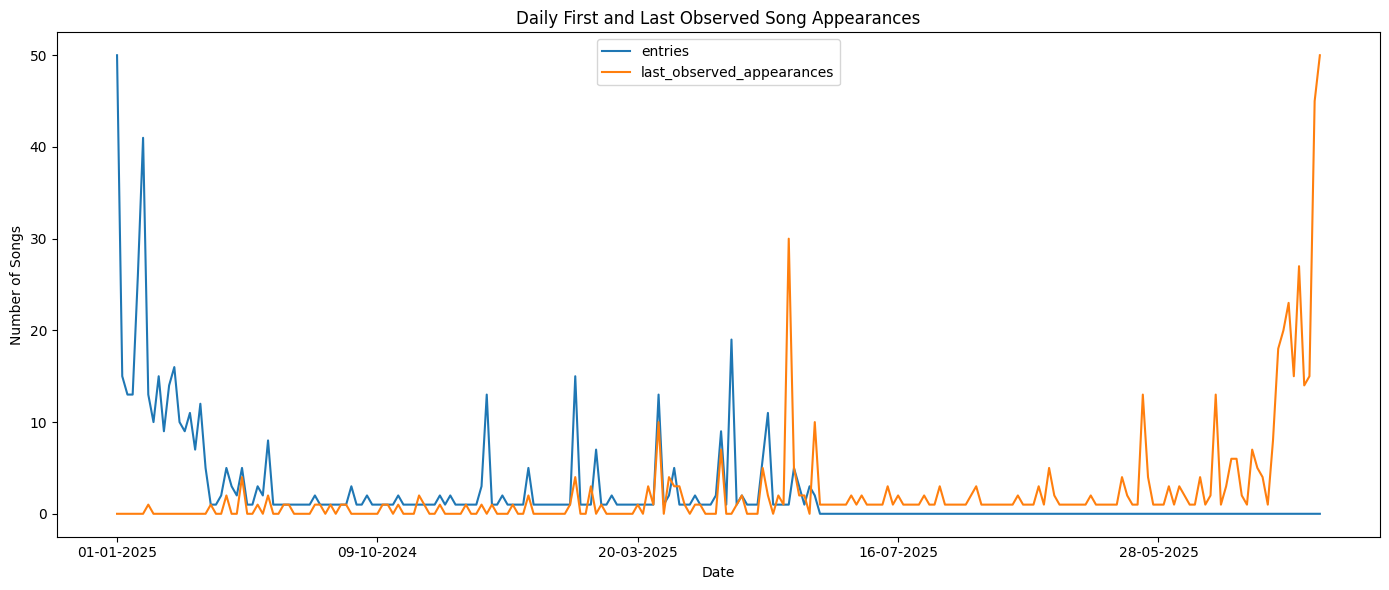

In [44]:
daily_movement.plot(
    figsize=(14, 6),
    linewidth=1.5
)

plt.title("Daily First and Last Observed Song Appearances")
plt.xlabel("Date")
plt.ylabel("Number of Songs")
plt.tight_layout()
plt.show()

In [45]:
print(song_lifecycle.columns.tolist())
print("Total songs:", len(song_lifecycle))

['song', 'entry_date', 'exit_date', 'observations', 'peak_position', 'peak_date']
Total songs: 545


In [56]:
lifecycle_kpis = pd.Series({
    "Unique songs analyzed": song_lifecycle["song"].nunique(),
    "Average observed playlist days": song_lifecycle["observations"].mean(),
    "Median observed playlist days": song_lifecycle["observations"].median(),
    "Average calendar span (days)": song_lifecycle["calendar_span_days"].mean(),
    "Average best ranking": song_lifecycle["peak_position"].mean()
})

display(lifecycle_kpis.round(2))


Unique songs analyzed             545.00
Average observed playlist days     50.90
Median observed playlist days      13.00
Average calendar span (days)       60.92
Average best ranking               21.77
dtype: float64

In [57]:
# Prepare the playlist snapshot data
required = {"date", "song"}

if required.issubset(df.columns):

    playlist = df.dropna(subset=["date", "song"]).copy()
    playlist["date"] = pd.to_datetime(
        playlist["date"], errors="coerce"
    )
    playlist = playlist.dropna(subset=["date"])

    # Use artist as part of the song identity when available
    if "artist" in playlist.columns:
        playlist["track_key"] = (
            playlist["song"].astype(str).str.strip()
            + " - "
            + playlist["artist"].fillna("").astype(str).str.strip()
        )
    else:
        playlist["track_key"] = (
            playlist["song"].astype(str).str.strip()
        )

    snapshots = {
        date: set(group["track_key"])
        for date, group in playlist.groupby("date")
    }

    dates = sorted(snapshots)
    movement_rows = []

    for i in range(1, len(dates)):
        previous_date = dates[i - 1]
        current_date = dates[i]

        previous_tracks = snapshots[previous_date]
        current_tracks = snapshots[current_date]

        new_tracks = current_tracks - previous_tracks
        missing_tracks = previous_tracks - current_tracks

        movement_rows.append({
            "date": current_date,
            "previous_snapshot_date": previous_date,
            "days_between_snapshots": (
                current_date - previous_date
            ).days,
            "new_entries": len(new_tracks),
            "disappearances": len(missing_tracks),
            "tracks_retained": len(
                previous_tracks & current_tracks
            )
        })

    daily_churn = pd.DataFrame(movement_rows)

    display(daily_churn.head(10))

else:
    print("The dataset must contain date and song columns.")

,date,previous_snapshot_date,days_between_snapshots,new_entries,disappearances,tracks_retained
0,2024-05-19,2024-05-18,1,0,0,50
1,2024-05-20,2024-05-19,1,0,0,50
2,2024-05-21,2024-05-20,1,4,4,46
3,2024-05-22,2024-05-21,1,1,1,49
4,2024-05-23,2024-05-22,1,0,0,50
5,2024-05-24,2024-05-23,1,0,0,50
6,2024-05-25,2024-05-24,1,2,2,48
7,2024-05-26,2024-05-25,1,1,1,49
8,2024-05-27,2024-05-26,1,1,1,49
9,2024-05-28,2024-05-27,1,5,5,45


In [58]:
if not daily_churn.empty:

    daily_churn["retention_rate_pct"] = (
        daily_churn["tracks_retained"]
        / daily_churn["tracks_retained"]
        .add(daily_churn["disappearances"])
        * 100
    )

    daily_churn["exit_rate_pct"] = (
        daily_churn["disappearances"]
        / daily_churn["tracks_retained"]
        .add(daily_churn["disappearances"])
        * 100
    )

    display(daily_churn.head(10))

    print(
        "Average observed retention rate:",
        round(daily_churn["retention_rate_pct"].mean(), 2),
        "%"
    )

    print(
        "Average observed exit rate:",
        round(daily_churn["exit_rate_pct"].mean(), 2),
        "%"
    )

else:
    print("Not enough snapshots to calculate retention and exit rates.")

,date,previous_snapshot_date,days_between_snapshots,new_entries,disappearances,tracks_retained,retention_rate_pct,exit_rate_pct
0,2024-05-19,2024-05-18,1,0,0,50,100.0,0.0
1,2024-05-20,2024-05-19,1,0,0,50,100.0,0.0
2,2024-05-21,2024-05-20,1,4,4,46,92.0,8.0
3,2024-05-22,2024-05-21,1,1,1,49,98.0,2.0
4,2024-05-23,2024-05-22,1,0,0,50,100.0,0.0
5,2024-05-24,2024-05-23,1,0,0,50,100.0,0.0
6,2024-05-25,2024-05-24,1,2,2,48,96.0,4.0
7,2024-05-26,2024-05-25,1,1,1,49,98.0,2.0
8,2024-05-27,2024-05-26,1,1,1,49,98.0,2.0
9,2024-05-28,2024-05-27,1,5,5,45,90.0,10.0


Average observed retention rate: 96.53 %
Average observed exit rate: 3.47 %


In [59]:
def classify_lifecycle(days):
    if days <= 7:
        return "Short-lived"
    elif days <= 30:
        return "Developing"
    else:
        return "Established"


song_lifecycle["lifecycle_stage"] = (
    song_lifecycle["observations"]
    .apply(classify_lifecycle)
)

stage_summary = (
    song_lifecycle["lifecycle_stage"]
    .value_counts()
    .rename_axis("Lifecycle Stage")
    .reset_index(name="Number of Songs")
)

stage_summary["Percentage"] = (
    stage_summary["Number of Songs"]
    / len(song_lifecycle) * 100
).round(2)

display(stage_summary)

,Lifecycle Stage,Number of Songs,Percentage
0,Short-lived,218,40.00
1,Established,204,37.43
2,Developing,123,22.57


In [60]:
print([
    col for col in df.columns
    if "explicit" in col.lower()
])

['is_explicit']


In [61]:
if "is_explicit" in df.columns:

    explicit_analysis = df.copy()

    explicit_analysis["position"] = pd.to_numeric(
        explicit_analysis["position"],
        errors="coerce"
    )

    explicit_summary = (
        explicit_analysis.groupby("is_explicit")
        .agg(
            playlist_records=("song", "size"),
            average_position=("position", "mean"),
            unique_songs=("song", "nunique")
        )
        .round(2)
    )

    display(explicit_summary)

else:
    print(
        "No explicit-content column found. "
        "We will revisit this comparison if the data supports it."
    )

,playlist_records,average_position,unique_songs
is_explicit,,,
False,16143,26.05,305
True,11657,24.74,246


In [62]:
print([
    col for col in df.columns
    if "album_type" in col.lower()
])

['album_type']


In [63]:
if "album_type" in df.columns:

    album_summary = (
        df.groupby("album_type", dropna=False)
        .agg(
            playlist_records=("song", "size"),
            unique_songs=("song", "nunique")
        )
        .reset_index()
    )

    display(album_summary)

else:
    print(
        "No album_type column found. "
        "We cannot perform this comparison directly yet."
    )

,album_type,playlist_records,unique_songs
0,album,11759,306
1,single,16041,280


In [67]:
from pathlib import Path

output_folder = Path("Documents/Spain_Top50_Analysis/Data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

song_lifecycle.to_csv(
    output_folder / "song_lifecycle_with_stages.csv",
    index=False
)

if "daily_churn" in globals() and not daily_churn.empty:
    daily_churn.to_csv(
        output_folder / "daily_churn.csv",
        index=False
    )

stage_summary.to_csv(
    output_folder / "lifecycle_stage_summary.csv",
    index=False
)

print("KPI analysis files saved successfully!")



KPI analysis files saved successfully!
